In [ ]:
%reload_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
import pyreadstat
from sklearn.decomposition import PCA
import statsmodels.api as sm
import pickle
import DCM

# Before run this file, set the uCRRA function as (x ** coef - 1) / coef.

In [2]:
# Clean the risky choice data

df_raw,raw_attr = pyreadstat.read_dta('../preference survey module/data/MainSample_Replication.dta')

# Recover answers to each question
# 1 - choosing lottery (A) -> higher sure payoff
# 0 - choosing sure payoff (B) -> lower sure payoff
# j: layer / order of choice question
# i: node in the current layer

j_max = 4

for j in range(j_max+1):
    for i in range(2**(j_max-j)):

        col_name = 'layer_' + str(j_max-j+1) + '_q' +str(i+1)

        conditions = [
            df_raw['v_110'].between((2*i)*2**j+1, (2*i+1)*2**j),   
            df_raw['v_110'].between((2*i+1)*2**j+1, (2*i+2)*2**j) 
        ]

        choice_labels = [0, 1]

        new_col = np.select(conditions, choice_labels, default=np.nan)
        
        df_raw = pd.concat([df_raw, pd.DataFrame({col_name: new_col})], axis=1)

# Melt the data: each row represent a choice 
df_raw = df_raw.reset_index(names='pid')

q_columns = [col for col in df_raw.columns if 'layer_' in col]

df_melted = df_raw.melt(id_vars='pid', value_vars=q_columns, 
                        var_name='q_risk', value_name='choice').dropna()

# Calculate the sure payoff for each question
def sure_pay(s):
    parts = s.strip().split('_')

    layer_number = j_max - int(parts[1]) + 1 
    q_number = int(parts[2][1:])

    return 2**(layer_number) + (q_number - 1)*2**(layer_number+1)


df_melted['x'] = df_melted['q_risk'].apply(sure_pay)*10
df_melted['layer'] = df_melted['q_risk'].apply(lambda x: x.strip().split('_')[1])

# Pivot the data
df_wide = df_melted[['pid','x','choice','layer']].pivot(index='pid', columns='layer', values=['x', 'choice'])

df_wide.columns = [f"layer_{col}_{layer}" for col, layer in df_wide.columns]
df_wide = df_wide.reset_index()

# Merge with the original levels
df_risk = pd.merge(right=df_raw[['pid','v_110']].dropna(),left=df_wide,on='pid')
print('Number of people in df_risk:',len(df_risk))

# Predict choices by the majority in each question
count_each_question = df_melted.groupby(['q_risk','x'])['choice'].count()
mean_choice = df_melted.groupby('q_risk')['choice'].mean()
accuracy_per_question = mean_choice * (mean_choice > 0.5) + (1 - mean_choice) * (mean_choice <= 0.5)
accuracy = (accuracy_per_question * count_each_question / count_each_question.sum()).sum()
print('Accuracy (majority of choices):', accuracy)

# This function generate model implied distribution for choice paths
def get_model_implied_dist(model,data,all_args):
    layer_like_list = [f'layer_like_{i}' for i in range(1,6)]
    layer_list = [f'layer_x_{i}' for i in range(1,6)] + layer_like_list

    data[layer_like_list] = model.choiceProb(all_args)

    df_const_like = data.groupby(layer_list).mean().reset_index()[layer_list]
    df_const_like['branch_0'] = 1

    for i in range(1,5):
        choice_option_one =(df_const_like[f'layer_x_{i+1}'] > df_const_like[f'layer_x_{i}'])
        cond_choice_prob = choice_option_one * df_const_like[f'layer_like_{i}'] + \
            (1-choice_option_one) * (1 - df_const_like[f'layer_like_{i}'])
        df_const_like[f'branch_{i}'] = df_const_like[f'branch_{i-1}'] * cond_choice_prob

    _encode = df_const_like.apply(lambda row: np.array([row['branch_4']* (1 - row['layer_like_5']), 
                                            row['branch_4'] * row['layer_like_5']]),axis=1).explode()
    _encode.index = np.arange(1,33)

    return _encode

Number of people in df_risk: 394
Accuracy (majority of choices): 0.6365482233502539


In [3]:
# Clean the intertemporal choice data

df_psm = pd.read_stata('../preference survey module/data/MainSample_Replication.dta')

# Recover answers to each question
# 1 - choosing SS (A) -> higher LL
# 0 - choosing LL (B) -> lower LL

df_psm['v_195'] = 32 - df_psm['v_195']

j_max = 4

for j in range(j_max+1):
    for i in range(2**(j_max-j)):

        col_name = 'layer_' + str(j_max-j+1) + '_q' +str(i+1)

        conditions = [
            df_psm['v_195'].between((2*i)*2**j+1, (2*i+1)*2**j),   
            df_psm['v_195'].between((2*i+1)*2**j+1, (2*i+2)*2**j) 
        ]

        choice_labels = [0, 1]

        new_col = np.select(conditions, choice_labels, default=np.nan)
        
        df_psm = pd.concat([df_psm, pd.DataFrame({col_name: new_col})], axis=1)

# Melt the data: each row represent a choice 
df_psm = df_psm.reset_index(names='pid')

q_columns = [col for col in df_psm.columns if 'layer_' in col]

df_melted = df_psm.melt(id_vars='pid', value_vars=q_columns, 
                        var_name='q_time', value_name='choice').dropna()

# Encode the LL payoff for each question
node_encoding_reverse = {
    (1, 1): 154,  # Layer 1 (Root), Node 1
    (2, 1): 125,  # Layer 2, Node 1 (Reversed)
    (2, 2): 185,  # Layer 2, Node 2 (Reversed)
    (3, 1): 112,  # Layer 3, Node 1 (Reversed)
    (3, 2): 139,  # Layer 3, Node 2 (Reversed)
    (3, 3): 169,  # Layer 3, Node 3 (Reversed)
    (3, 4): 202,  # Layer 3, Node 4 (Reversed)
    (4, 1): 106,  # Layer 4, Node 1 (Reversed)
    (4, 2): 119,  # Layer 4, Node 2 (Reversed)
    (4, 3): 132,  # Layer 4, Node 3 (Reversed)
    (4, 4): 146,  # Layer 4, Node 4 (Reversed)
    (4, 5): 161,  # Layer 4, Node 5 (Reversed)
    (4, 6): 177,  # Layer 4, Node 6 (Reversed)
    (4, 7): 193,  # Layer 4, Node 7 (Reversed)
    (4, 8): 210,  # Layer 4, Node 8 (Reversed)
    (5, 1): 103,  # Layer 5, Node 1 (Reversed)
    (5, 2): 109,  # Layer 5, Node 2 (Reversed)
    (5, 3): 116,  # Layer 5, Node 3 (Reversed)
    (5, 4): 129,  # Layer 5, Node 4 (Reversed)
    (5, 5): 122,  # Layer 5, Node 5 (Reversed)
    (5, 6): 136,  # Layer 5, Node 6 (Reversed)
    (5, 7): 143,  # Layer 5, Node 7 (Reversed)
    (5, 8): 150,  # Layer 5, Node 8 (Reversed)
    (5, 9): 158,  # Layer 5, Node 9 (Reversed)
    (5, 10): 165, # Layer 5, Node 10 (Reversed)
    (5, 11): 173, # Layer 5, Node 11 (Reversed)
    (5, 12): 181, # Layer 5, Node 12 (Reversed)
    (5, 13): 189, # Layer 5, Node 13 (Reversed)
    (5, 14): 197, # Layer 5, Node 14 (Reversed)
    (5, 15): 206, # Layer 5, Node 15 (Reversed)
    (5, 16): 215  # Layer 5, Node 16 (Reversed)
}

def LL_pay(s):
    parts = s.strip().split('_')

    layer_number = int(parts[1])
    q_number = int(parts[2][1:])

    return node_encoding_reverse.get((layer_number, q_number), "Node not found")


df_melted['x'] = df_melted['q_time'].apply(LL_pay)
df_melted['layer'] = df_melted['q_time'].apply(lambda x: x.strip().split('_')[1])

# Pivot the data
df_wide = df_melted[['pid','x','choice','layer']].pivot(index='pid', columns='layer', values=['x', 'choice'])

df_wide.columns = [f"layer_{col}_{layer}" for col, layer in df_wide.columns]
df_wide = df_wide.reset_index()

# Merge with the original levels
df_time = pd.merge(right=df_psm[['pid','v_195']].dropna(),left=df_wide,on='pid')
print('Number of people in df_time:', len(df_time))

# Predict choices by the majority in each question
count_each_question = df_melted.groupby('q_time')['choice'].count()
mean_choice = df_melted.groupby('q_time')['choice'].mean()
accuracy_per_question = mean_choice * (mean_choice > 0.5) + (1 - mean_choice) * (mean_choice <= 0.5)
accuracy = (accuracy_per_question * count_each_question / count_each_question.sum()).sum()
print('Accuracy (majority of choices):', accuracy)

Number of people in df_time: 353
Accuracy (majority of choices): 0.6113314447592069


C:\Users\zarkwang\AppData\Local\Temp\ipykernel_6012\3441419668.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_psm = df_psm.reset_index(names='pid')


In [11]:
# Test preference heterogeneity for risky choices
tab_count = df_raw['v_110'].value_counts()
tab_count.index = tab_count.index.astype(int).astype(str)

prop_test = DCM.proportionTest(tab_count)
prop_test.run(hide=True)
prop_test.get_power(method='fisher')
prop_test.get_power(method='barnard')
prop_test.result.to_csv('prop_result_risk.csv')

print('Fisher p-value:',prop_test.get_overall_pvalue(method='fisher')) 
print('Barnard p-value:',prop_test.get_overall_pvalue(method='barnard')) 
print(prop_test.result[['layer','group','prop_lo','prop_0','prop_hi','p_fisher','p_barnard','power_fisher','power_barnard']])

Fisher p-value: 0.1326768954536934
Barnard p-value: 0.09170139821242043
    layer  group   prop_lo    prop_0   prop_hi  p_fisher  p_barnard  \
5       3      6  1.000000  0.888889  0.375000  1.000000   1.000000   
6       3      7  0.333333  0.538462  0.000000  1.000000   1.000000   
13      0      1  0.492013  0.205584  0.246914  0.999986   1.000000   
3       3      4  0.480000  0.637681  0.181818  0.997971   1.000000   
11      1      1  0.547170  0.492013  0.448052  0.969095   1.000000   
2       3      3  0.770833  0.435294  0.621622  0.958586   1.000000   
10      2      4  0.538462  0.350000  0.285714  0.942105   1.000000   
7       2      1  0.583333  0.547170  0.505747  0.872307   1.000000   
1       3      2  0.465116  0.505747  0.454545  0.623165   1.000000   
0       3      1  0.566667  0.583333  0.595238  0.499084   0.450650   
4       3      5  0.227273  0.576923  0.400000  0.155697   0.222948   
12      1      2  0.147541  0.246914  0.350000  0.053578   0.211629   
9    

In [12]:
# Test preference heterogeneity for intertemporal choices
tab_count = df_time['v_195'].value_counts()
tab_count.index = tab_count.index.astype(int).astype(str)

prop_test = DCM.proportionTest(tab_count)
prop_test.run(hide=True)
prop_test.get_power(method='fisher')
prop_test.get_power(method='barnard')
prop_test.result.to_csv('prop_result_time.csv')

print('Fisher p-value:',prop_test.get_overall_pvalue(method='fisher')) 
print('Barnard p-value:',prop_test.get_overall_pvalue(method='barnard')) 
print(prop_test.result[['layer','group','prop_lo','prop_0','prop_hi','p_fisher','p_barnard','power_fisher','power_barnard']])

Fisher p-value: 0.019067537159116958
Barnard p-value: 0.017211487665114635
    layer  group   prop_lo    prop_0   prop_hi  p_fisher  p_barnard  \
3       3      4  0.642857  0.416667  0.100000  0.999490   1.000000   
7       2      1  0.794118  0.507246  0.457143  0.999276   1.000000   
1       3      2  0.526316  0.457143  0.187500  0.993292   1.000000   
8       2      2  0.714286  0.461538  0.416667  0.993117   1.000000   
10      2      4  0.487179  0.442857  0.338710  0.974176   1.000000   
9       2      3  0.681818  0.521739  0.541667  0.944460   1.000000   
12      1      2  0.521739  0.603448  0.442857  0.905157   1.000000   
5       3      6  0.500000  0.541667  0.423077  0.794790   1.000000   
11      1      1  0.507246  0.429752  0.461538  0.752136   1.000000   
4       3      5  0.357143  0.681818  0.400000  0.527781   0.427341   
2       3      3  0.375000  0.714286  0.450000  0.527536   0.389426   
0       3      1  0.428571  0.794118  0.888889  0.020436   0.137878   
6 

In [81]:
raw_attr.column_names_to_labels

{'v_150': 'Time: willingness to wait',
 'v_151': 'Time: willingness to wait compared to others',
 'v_152': 'Time: willingness to wait assessed by others',
 'v_153': 'Time: willingness to wrt financial decisions',
 'v_154': 'Time: willingness to wait wrt important life decisions',
 'v_155': 'Time: willingness to wait wrt career',
 'v_156': 'Time: willingness to wait wrt big purchases',
 'v_157': 'Time: willingness to wait wrt bigger vacation',
 'v_158': 'Time: I make decisions I later regret.',
 'v_159': 'Time: I often think about the future.',
 'v_160': 'Time: It is hard to abstain from unhealthy tasty food.',
 'v_161': 'Time: Dont care about tomorrow, only today matters',
 'v_162': 'Time: I often regret decisions that I make',
 'v_163': 'Time: I often act hastily',
 'v_164': 'Time: I save for retirement',
 'v_165': 'Time: I dont find it hard to resist temptation',
 'v_166': 'Time: I spend too much money.',
 'v_167': 'Time: I eat too much.',
 'v_168': 'Time: I dont work out enough.',
 

In [8]:
# Model estimation for risky choices
x_cols = [col for col in df_risk.columns if 'layer_x' in col]
choice_cols = [col for col in df_risk.columns if 'layer_choice' in col]
bounds = [(None,1),(0,None)]

model = DCM.mixedDiscrete(data=df_risk,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5)

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,1.0])
model.fit_param(bounds=bounds)
pred_const_model_risk = model.predict()
pred_const_model_risk['approx_log_like'] = model.result.fun / 1000

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 1299917.7107288463
        x: [ 3.816e-01  8.439e+00]
      nit: 19
      jac: [ 2.328e-02 -4.657e-02]
     nfev: 78
     njev: 26
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [10]:
bounds = [(None,1)]

model = DCM.mixedDiscrete(data=df_risk,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':8.4})


model.set_init_param(param_keys=['riskCoef'],param_init=[0.5])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 1299918.157608409
        x: [ 3.805e-01]
      nit: 6
      jac: [-4.657e-02]
     nfev: 22
     njev: 11
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [11]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 8.4],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm/risk_unconstrained')

Searching optimal value for temp
Step 1: 5.666666666666667
Evaluation metrics: 1496.0449420706318, 1406.1066247424112
Step 2: 6.577777777777778
Evaluation metrics: 1414.2972930167668, 1361.306399508112
Step 3: 7.185185185185185
Evaluation metrics: 1406.0849675695886, 1360.458249397313
Step 4: 7.590123456790124
Evaluation metrics: 1407.8688679754805, 1366.5892192769033
Step 5: 7.3201646090534975
Evaluation metrics: 1361.3837746502843, 1414.535614029974
Step 6: 7.140192043895748
Evaluation metrics: 1360.143642652009, 1410.0679272527213
Step 7: 7.0202103337905815
Evaluation metrics: 1359.3026300132074, 1409.2571693499115
Step 8: 6.940222527053804
Evaluation metrics: 1358.7307855080212, 1359.864690481508
Step 9: 6.886897322562618
Evaluation metrics: 1358.346712702746, 1408.4825975316103
Step 10: 6.851347186235161
Evaluation metrics: 1358.0876016605228, 1358.6029314720658


({'temp': 6.851347186235161}, np.float64(1358.0876880292071))

In [12]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 8.4],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm/risk_unconstrained')

Searching optimal value for temp
Step 1: 5.666666666666667
Evaluation metrics: 1665.685118973683, 1459.0497555605582
Step 2: 4.755555555555556
Evaluation metrics: 1448.4913544999395, 1504.9709688398875
Step 3: 4.148148148148149
Evaluation metrics: 1439.4485728093402, 1455.8311542708977
Step 4: 4.553086419753088
Evaluation metrics: 1611.9574246782686, 1445.6846136347895
Step 5: 4.283127572016461
Evaluation metrics: 1441.6336537544337, 1449.3697895238533
Step 6: 4.103155006858712
Evaluation metrics: 1438.714372463506, 1444.3616012307175
Step 7: 3.9831732967535447
Evaluation metrics: 1436.7098082707428, 1440.7225193438478
Step 8: 3.903185490016767
Evaluation metrics: 1435.374845598661, 1438.0624030655058
Step 9: 3.8498602855255815
Evaluation metrics: 1434.4063453248023, 1436.2911163479832
Step 10: 3.885410421853038
Evaluation metrics: 1632.4222803235557, 1435.0278875771858


({'temp': 3.885410421853038}, np.float64(1435.0292408345304))

In [13]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 8.4],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm/risk_unconstrained')

Searching optimal value for temp
Step 1: 5.666666666666667
Evaluation metrics: 1661.3885974730038, 1646.8140055911638
Step 2: 4.755555555555556
Evaluation metrics: 1625.7206965216774, 1667.0699125245367
Step 3: 4.148148148148149
Evaluation metrics: 1602.3329219272505, 1640.7690992166727
Step 4: 4.553086419753088
Evaluation metrics: 1745.1170183120767, 1618.2044541214113
Step 5: 4.283127572016461
Evaluation metrics: 1615.5914541127595, 1628.329532144844
Step 6: 4.103155006858712
Evaluation metrics: 1602.2254989332012, 1615.0529859051794
Step 7: 3.9831732967535447
Evaluation metrics: 1599.0702002806613, 1610.1529937687596
Step 8: 3.903185490016767
Evaluation metrics: 1596.1377914533562, 1605.304655082954
Step 9: 3.8498602855255815
Evaluation metrics: 1595.208665822914, 1607.5491549614908
Step 10: 3.885410421853038
Evaluation metrics: 1742.6593760309988, 1596.695076931986


({'temp': 3.885410421853038}, np.float64(1603.9513628486948))

In [14]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 8.4],
                     n_class=5, n_init_point = 8, name_prefix = 'models_psm/risk_unconstrained')

Searching optimal value for temp
Step 1: 5.666666666666667
Evaluation metrics: 1784.0447148082449, 1773.4514348139976
Step 2: 4.755555555555556
Evaluation metrics: 1753.483208131456, 1788.4475782890008
Step 3: 4.148148148148149
Evaluation metrics: 1737.6471349742574, 1760.7613912148163
Step 4: 3.7432098765432107
Evaluation metrics: 1735.8610112186125, 1748.2798804782612
Step 5: 4.013168724279836
Evaluation metrics: 1771.4832497557995, 1731.0404876522907
Step 6: 3.833196159122086
Evaluation metrics: 1725.1312166734515, 1736.279665699463
Step 7: 3.7132144490169194
Evaluation metrics: 1622.0052812112663, 1729.8259223796663
Step 8: 3.6332266422801416
Evaluation metrics: 1629.342105622892, 1788.092044954088
Step 9: 3.5799014377889558
Evaluation metrics: 1757.6799796443952, 1768.26962512044
Step 10: 3.615451574116413
Evaluation metrics: 1787.711805562948, 1748.859325799099


({'temp': 3.615451574116413}, np.float64(1752.5575137156359))

In [15]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 8.4],
                     n_class=6, n_init_point = 8, name_prefix = 'models_psm/risk_unconstrained')

Searching optimal value for temp
Step 1: 2.933333333333333
Evaluation metrics: 1808.2970660026763, 1865.0338270317372
Step 2: 3.844444444444444
Evaluation metrics: 1927.8185999630073, 1814.84795035653
Step 3: 4.451851851851851
Evaluation metrics: 1867.344144276136, 1833.8977850111269
Step 4: 4.046913580246914
Evaluation metrics: 1820.9282552976592, 1844.8682399095087
Step 5: 3.7769547325102875
Evaluation metrics: 1660.7837400700719, 1828.9713072062773
Step 6: 3.596982167352537
Evaluation metrics: 1807.6261637455627, 1818.624935136273
Step 7: 3.47700045724737
Evaluation metrics: 1661.719205429033, 1699.9726300998034
Step 8: 3.556988263984148
Evaluation metrics: 1825.983405782935, 1798.8115740979392
Step 9: 3.6103134684753337
Evaluation metrics: 1870.2030132681878, 1671.400396053712
Step 10: 3.6458636048027904
Evaluation metrics: 1822.4410403879472, 1655.7314503168272


({'temp': 3.6458636048027904}, np.float64(1823.5853785374038))

In [ ]:
x_cols = [col for col in df_risk.columns if 'layer_x' in col]
choice_cols = [col for col in df_risk.columns if 'layer_choice' in col]

model = DCM.mixedNormal(data=df_risk,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5
                )

model.set_init_mixed(meta_param = {'mean':[0.38],'variance':[[1.0]]}, 
                     param_keys= ['riskCoef'],
                     dist_type=['johnson_sb'],
                     constant_param={'temp':8.4},
                     n_draws = 200,
                     n_batch = 5)

model.runEM(max_iter=100)

model.simuIndivParam(optim=True)
pickle.dump(model, open(f'models_psm/risk_normal.pkl', 'wb'))

In [18]:
print('const params:',pred_const_model_risk)
for i in range(2,7):
    model = pickle.load(open(f'models_psm/risk_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)


# normal_model = pickle.load(open('models_psm/risk_normal.pkl', 'rb'))
# pred_normal = normal_model.choicePred()
# pred_normal['approx_log_like'] = normal_model.obj_func
# print('normal:',pred_normal)

const params: {'accuracy': np.float64(0.5979695431472083), 'RMSE': np.float64(0.23368193240742424), 'cross-entropy': np.float64(0.6598567059537289), 'approx_log_like': np.float64(1299.9177107288463)}
model 2: {'accuracy': np.float64(0.7076142131979697), 'RMSE': np.float64(0.21965033439813403), 'cross-entropy': np.float64(0.6360428190054677), 'approx_log_like': np.float64(1399.8360382975984)}
model 3: {'accuracy': np.float64(0.6162436548223351), 'RMSE': np.float64(0.2477488682813581), 'cross-entropy': np.float64(0.6919881556397881), 'approx_log_like': np.float64(1563.7162731054698)}
model 4: {'accuracy': np.float64(0.5979695431472083), 'RMSE': np.float64(0.24064117204991234), 'cross-entropy': np.float64(0.6721140940272932), 'approx_log_like': np.float64(1633.0309232634945)}
model 5: {'accuracy': np.float64(0.6040609137055838), 'RMSE': np.float64(0.25598956183167776), 'cross-entropy': np.float64(0.7143386298523344), 'approx_log_like': np.float64(1784.9146022665166)}
model 6: {'accuracy':

In [ ]:
risk_col_list = [f'v_{i}' for i in range(94,103)]
df_raw_risk = df_raw[df_raw['pid'].isin(df_risk['pid'])]
# df_raw_risk = df_raw_risk[df_raw_risk['v_110'] <= 16]
df_raw_risk['isRiskSeeking'] = df_raw_risk['v_110'] >= 16

# PCA
pca = PCA(n_components=3)
principal_components = pca.fit_transform(df_raw_risk[risk_col_list])
df_raw_risk['willing_risk'] = principal_components[:,0]

print("Explained Variance Ratio:", pca.explained_variance_ratio_)

# Get expected individual-level parameters
model = pickle.load(open('models_psm/risk_unconstrained_class_2.pkl', 'rb'))
df_raw_risk['riskCoef'] = 1 - (model.post_prob * model.latent_class['riskCoef']).sum(axis=1)
df_raw_risk[f'riskCoefRiskSeek'] = df_raw_risk['riskCoef'] * df_raw_risk['isRiskSeeking']

# Regression on incentivized-choice-based preference measure
controls = df_raw_risk.iloc[:,np.where(df_raw_risk.columns == 'v_103')[0][0]:np.where(df_raw_risk.columns == 'v_119')[0][0]]

df_raw_risk_edited = df_raw_risk[df_raw_risk['x_risk_av'].notna()]
exo_var = ['isRiskSeeking','riskCoef','riskCoefRiskSeek']

exog = sm.add_constant(df_raw_risk_edited[exo_var].astype(float))
endog = df_raw_risk_edited['x_risk_av']

reg_model = sm.OLS(endog,exog).fit().get_robustcov_results(cov_type='HC1')
reg_model.summary()

Explained Variance Ratio: [0.4329566  0.13639427 0.11762784]


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              x_risk_av   R-squared:                       0.091
Model:                            OLS   Adj. R-squared:                  0.084
Method:                 Least Squares   F-statistic:                     12.71
Date:                Sat, 11 Apr 2026   Prob (F-statistic):           6.21e-08
Time:                        16:35:26   Log-Likelihood:                -947.84
No. Observations:                 382   AIC:                             1904.
Df Residuals:                     378   BIC:                             1919.
Df Model:                           3                                         
Covariance Type:                  HC1                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               12.3018      0.659     18.672      0.000      11.006      13.597
isRiskSeeking       -1.5124      1.813     -0.834      0.405      -5.076       2.052
riskCoef            -3.9947      1.121     -3.563      0.000      -6.199      -1.790
riskCoefRiskSeek     5.5430      2.921      1.898      0.058      -0.200      11.286
==============================================================================
Omnibus:                       30.711   Durbin-Watson:                   1.950
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               64.291
Skew:                           0.441   Prob(JB):                     1.09e-14
Kurtosis:                       4.806   Cond. No.                         35.7
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC1)
"""

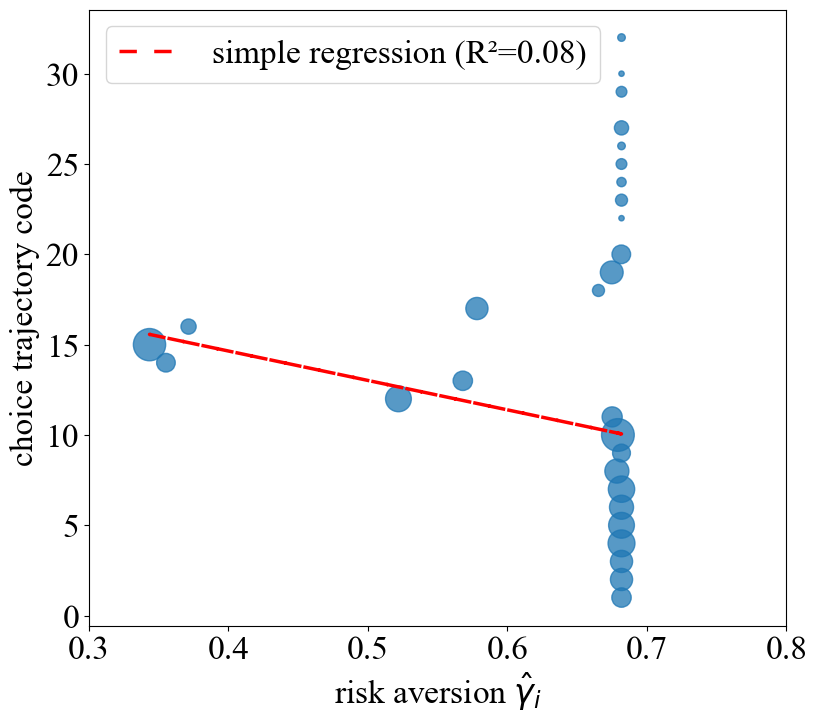

min riskCoef: 0.3434456003859231
max riskCoef: 0.6818019549564478
PearsonRResult(statistic=np.float64(-0.28365087549008006), pvalue=np.float64(1.0011133461595262e-08))
for risk-averse subgroup:
slope: -27.286062333362374
R²: 0.6328251990978027
PearsonRResult(statistic=np.float64(-0.7955031106776408), pvalue=np.float64(1.2345209484775364e-69))


In [30]:
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 24
plt.figure(figsize=(9, 8))

df_scatter_risk = df_raw_risk.groupby(['riskCoef','v_110']).count()['pid'].reset_index()
plt.scatter(df_scatter_risk['riskCoef'],df_scatter_risk['v_110'],
            s=df_scatter_risk['pid']*15, marker='o', alpha=.75)
plt.xlabel(r'risk aversion $\hat{\gamma}_i$')
plt.ylabel('choice trajectory code')
plt.xlim((0.3,0.8))

slope, intercept, r, p_value, std_err = st.linregress(x=df_raw_risk['riskCoef'], y=df_raw_risk['v_110'])
pred_subgroup = slope * df_raw_risk['riskCoef'] + intercept
plt.plot(df_raw_risk['riskCoef'], pred_subgroup, color='red', linestyle=(0,(5,5)), linewidth = 2.5, 
         label= f"simple regression (R²={r**2:.2f})")

plt.legend(loc='best')
plt.show()

print('min riskCoef:',df_raw_risk['riskCoef'].min())
print('max riskCoef:',df_raw_risk['riskCoef'].max())
print(st.pearsonr(df_raw_risk['riskCoef'],df_raw_risk['v_110']))


print('for risk-averse subgroup:')
df_raw_risk_edited = df_raw_risk[df_raw_risk['v_110'] <=16]
slope, intercept, r, p_value, std_err = st.linregress(x=df_raw_risk_edited['riskCoef'], y=df_raw_risk_edited['v_110'])
print('slope:', slope)
print('R²:', r**2)
print(st.pearsonr(df_raw_risk_edited['riskCoef'],df_raw_risk_edited['v_110']))

In [ ]:
# Model estimation for intertemporal choices
x_cols = [col for col in df_time.columns if 'layer_x' in col]
choice_cols = [col for col in df_time.columns if 'layer_choice' in col]
bounds = [(0,1),(0,None)]

model = DCM.mixedDiscrete(data=df_time,
                choice = choice_cols,
                x1 = 100,
                x2 = x_cols,
                t2 = 1,
                fixed_args= {'riskCoef':.382}
                )

model.set_init_param(param_keys=['delta','temp'],param_init=[0.5,1.0])
model.fit_param()
pred_const_model_time = model.predict()
pred_const_model_time['approx_log_like'] = model.result.fun / 1000

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 1215171.795226053
        x: [ 7.264e-01  5.111e+00]
      nit: 20
      jac: [-3.097e+00 -4.657e-02]
     nfev: 66
     njev: 22
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [ ]:
# Treat temp as a fixed argument  
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_time,
                choice = choice_cols,
                x1 = 100,
                x2 = x_cols,
                t2 = 1,
                fixed_args= {'riskCoef':.382,'temp': 5.1}
                )

model.set_init_param(param_keys=['delta'],param_init=[0.5])
model.fit_param()

  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 1215171.8139753125
        x: [ 7.266e-01]
      nit: 4
      jac: [ 0.000e+00]
     nfev: 12
     njev: 6
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [ ]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 5.2],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm/time_unconstrained')

Searching optimal value for temp
Step 1: 1.8666666666666667
Evaluation metrics: 1357.9764949316411, 1460.5686443064296
Step 2: 1.3111111111111113
Evaluation metrics: 1350.0071003987314, 1372.5796857326043
Step 3: 0.9407407407407408
Evaluation metrics: 1318.651466167578, 1360.5218956869317
Step 4: 0.6938271604938272
Evaluation metrics: 1287.4704556162878, 1341.880123387562
Step 5: 0.5292181069958848
Evaluation metrics: 1268.0805209955095, 1308.9292275611483
Step 6: 0.41947873799725655
Evaluation metrics: 1264.9601585733556, 1280.3218584731032
Step 7: 0.49263831732967533
Evaluation metrics: 1275.6215419545151, 1265.4869194256823
Step 8: 0.4438652644413961
Evaluation metrics: 1264.2330014718834, 1269.1710607492582
Step 9: 0.47638063303358225
Evaluation metrics: 1265.4777968279989, 1264.738445665358
Step 10: 0.4547037206387915
Evaluation metrics: 1264.2371652964412, 1265.7963883981497


({'temp': 0.4547037206387915}, 1264.2373733925815)

In [ ]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 5.2],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm/time_unconstrained')

Searching optimal value for temp
Step 1: 1.8666666666666667
Evaluation metrics: 1548.798193831488, 1603.7435213099136
Step 2: 1.3111111111111113
Evaluation metrics: 1513.6283359027052, 1566.7321031942101
Step 3: 0.9407407407407408
Evaluation metrics: 1393.072896399126, 1543.1106363484728
Step 4: 0.6938271604938272
Evaluation metrics: 1370.4798091296152, 1414.7244265632535
Step 5: 0.5292181069958848
Evaluation metrics: 1369.8250200720443, 1424.0183722619356
Step 6: 0.41947873799725655
Evaluation metrics: 1332.9835556830308, 1381.9502089041166
Step 7: 0.34631915866483765
Evaluation metrics: 1304.7779303803115, 1359.205646294781
Step 8: 0.2975461057765585
Evaluation metrics: 1288.5541066744572, 1323.5160593297337
Step 9: 0.2650307371843723
Evaluation metrics: 1281.1305587515885, 1298.9272347253814
Step 10: 0.24335382478958154
Evaluation metrics: 1278.723005186519, 1285.6671268358698


({'temp': 0.24335382478958154}, 1278.723065683066)

In [ ]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 5.2],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm/time_unconstrained')

Searching optimal value for temp
Step 1: 1.8666666666666667
Evaluation metrics: 1656.9666341102081, 1705.2555314147808
Step 2: 1.3111111111111113
Evaluation metrics: 1607.7750875942738, 1680.171896292859
Step 3: 0.9407407407407408
Evaluation metrics: 1556.1610426080256, 1626.1654833734517
Step 4: 0.6938271604938272
Evaluation metrics: 1516.6211345738507, 1598.9211555667764
Step 5: 0.5292181069958848
Evaluation metrics: 1475.8096403379395, 1565.4949573715508
Step 6: 0.41947873799725655
Evaluation metrics: 1413.0591699837948, 1519.7500010845376
Step 7: 0.34631915866483765
Evaluation metrics: 1408.0257577721754, 1419.586004846022
Step 8: 0.2975461057765585
Evaluation metrics: 1349.4299281280241, 1394.5783558915005
Step 9: 0.2650307371843723
Evaluation metrics: 1324.7779583232536, 1367.5071553419746
Step 10: 0.24335382478958154
Evaluation metrics: 1306.982390501434, 1341.0018473995062


({'temp': 0.24335382478958154}, 1306.9823459587828)

In [ ]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 5.2],
                     n_class=5, n_init_point = 8, name_prefix = 'models_psm/time_unconstrained')

Searching optimal value for temp
Step 1: 1.8666666666666667
Evaluation metrics: 1735.5509196222383, 1784.0523126396915
Step 2: 1.3111111111111113
Evaluation metrics: 1687.3359183367836, 1757.244751983653
Step 3: 0.9407407407407408
Evaluation metrics: 1594.7438596638583, 1711.9090924845877
Step 4: 0.6938271604938272
Evaluation metrics: 1587.0683472785204, 1666.614888263544
Step 5: 0.5292181069958848
Evaluation metrics: 1544.069943085039, 1622.2820526304713
Step 6: 0.41947873799725655
Evaluation metrics: 1511.4530511830292, 1580.1867816060353
Step 7: 0.34631915866483765
Evaluation metrics: 1475.9065163316657, 1526.7471916748132
Step 8: 0.2975461057765585
Evaluation metrics: 1420.5661076688516, 1490.5431354039465
Step 9: 0.2650307371843723
Evaluation metrics: 1366.314780072692, 1458.1405861315382
Step 10: 0.24335382478958154
Evaluation metrics: 1366.4449433090465, 1371.6821986629611


({'temp': 0.24335382478958154}, np.float64(1333.2479414966863))

In [ ]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 5.2],
                     n_class=6, n_init_point = 8, name_prefix = 'models_psm/time_unconstrained')

Searching optimal value for temp
Step 1: 1.8666666666666667
Evaluation metrics: 1791.5021002713495, 1848.4039071131288
Step 2: 1.3111111111111113
Evaluation metrics: 1747.6607301547306, 1825.1971717365327
Step 3: 0.9407407407407408
Evaluation metrics: 1685.6310584972034, 1779.4600410054413
Step 4: 0.6938271604938272
Evaluation metrics: 1649.8930749459735, 1733.516547813804
Step 5: 0.5292181069958848
Evaluation metrics: 1603.5508502772623, 1672.6674128930658
Step 6: 0.41947873799725655
Evaluation metrics: 1555.5393289878807, 1637.1451599142279
Step 7: 0.34631915866483765
Evaluation metrics: 1511.8912609676327, 1585.6560854570544
Step 8: 0.2975461057765585
Evaluation metrics: 1479.401554209935, 1546.4352441281903
Step 9: 0.2650307371843723
Evaluation metrics: 1433.8448653501218, 1501.0577828520954
Step 10: 0.24335382478958154
Evaluation metrics: 1410.207904520157, 1460.811922567471


({'temp': 0.24335382478958154}, 1411.3680450982479)

In [ ]:
x_cols = [col for col in df_time.columns if 'layer_x' in col]
choice_cols = [col for col in df_time.columns if 'layer_choice' in col]

model = DCM.mixedNormal(data=df_time,
                choice = choice_cols,
                x1 = 100,
                x2 = x_cols,
                t2 = 1,
                fixed_args= {'riskCoef':.382}
                )

model.set_init_mixed(meta_param = {'mean':[0.73],'variance':[[1.0]]}, 
                     param_keys= ['delta'],
                     dist_type=['johnson_sb'],
                     constant_param={'temp':5.1},
                     n_draws = 200,
                     n_batch = 5)

model.runEM(max_iter=100)

model.simuIndivParam(optim=True)
pickle.dump(model, open(f'models_psm/time_normal.pkl', 'wb'))

Iteration 1
{'mean': [0.7995522296990839], 'variance': array([[0.95305314]])}
gradient: (array([9.76996262e-15]), array([[3.50830476e-14]]))
objective: 1246.9183902128548
constants: {'temp': 5.099998678651858}
const_obj: 1247.7867766275567
Iteration 2
{'mean': [0.851679672173939], 'variance': array([[0.91403219]])}
gradient: (array([-2.30926389e-14]), array([[5.21804822e-14]]))
objective: 1245.1249965674288
constants: {'temp': 5.09999897907355}
const_obj: 1245.3619884818963
Iteration 3
{'mean': [0.8978555759984712], 'variance': array([[0.87944409]])}
gradient: (array([5.77315973e-14]), array([[-9.65894031e-15]]))
objective: 1242.7220798628118
constants: {'temp': 5.099997243248425}
const_obj: 1243.224039579551
Iteration 4
{'mean': [0.9360783436037529], 'variance': array([[0.84587608]])}
gradient: (array([1.19904087e-13]), array([[-6.60027588e-14]]))
objective: 1241.1149532544277
constants: {'temp': 5.099999564017161}
const_obj: 1241.1596303029226
Iteration 5
{'mean': [0.9640383336140834

In [183]:
print('benchmark cross-entropy:', - np.log(0.5))
print('const params:',pred_const_model_time)
for i in range(2,7):
    model = pickle.load(open(f'models_psm/time_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)

# plt.hist((model.post_prob * model.latent_class['delta']).sum(axis=1),bins=20)

normal_model = pickle.load(open('models_psm/time_normal.pkl', 'rb'))
pred_normal = normal_model.choicePred()
pred_normal['approx_log_like'] = normal_model.obj_func
print('normal:',pred_normal)

benchmark cross-entropy: 0.6931471805599453
const params: {'accuracy': 0.5569405099150141, 'RMSE': 0.24766948363351937, 'cross-entropy': 0.6884826035275088, 'approx_log_like': 1215.171795226053}
model 2: {'accuracy': 0.6940509915014165, 'RMSE': 0.18782459298123239, 'cross-entropy': 0.5516761944177258, 'approx_log_like': 1264.2373733925815}
model 3: {'accuracy': 0.7648725212464589, 'RMSE': 0.19493190959481566, 'cross-entropy': 0.5772944876581114, 'approx_log_like': 1465.2391302242286}
model 4: {'accuracy': 0.8424929178470255, 'RMSE': 0.13542691653757494, 'cross-entropy': 0.42703233741987034, 'approx_log_like': 1306.9823459587828}
model 5: {'accuracy': 0.8424929178470255, 'RMSE': 0.13542680331716872, 'cross-entropy': 0.4270320640145394, 'approx_log_like': 1333.2479414966863}
model 6: {'accuracy': 0.8424929178470255, 'RMSE': 0.13542682881570262, 'cross-entropy': 0.4270321271977683, 'approx_log_like': 1411.3680450982479}
normal: {'accuracy': 0.5643059490084985, 'RMSE': 0.24765437797195428,

In [7]:
time_col_list = [col for col in raw_attr.column_names[:8]]
df_raw_time = df_raw[df_raw['pid'].isin(df_time['pid'])]

# standardize the data
# scaler = StandardScaler()
# scaled_data = scaler.fit_transform(df_raw_time)

# PCA
pca = PCA(n_components=3)
principal_components = pca.fit_transform(df_raw_time[time_col_list])

print("Explained Variance Ratio:", pca.explained_variance_ratio_)


# Correlation between riskCoef and temp in dual-parameter joint estimation
tmp_model = pickle.load(open('models_psm/time_class_4_2param.pkl', 'rb'))
tmp_delta = (tmp_model.post_prob * tmp_model.latent_class['delta']).sum(axis=1)
tmp_temp = (tmp_model.post_prob * tmp_model.latent_class['temp']).sum(axis=1)
print(st.pearsonr(tmp_delta,tmp_temp))

# Regression
model = pickle.load(open('models_psm/time_class_4.pkl', 'rb'))
df_raw_time['willing_wait'] = principal_components[:,0]

df_raw_time['delta'] = (model.post_prob * model.latent_class['delta']).sum(axis=1)

# endog = df_raw_time['willing_wait']

df_raw_time_edited = df_raw_time[df_raw_time['x_time_0_12_av'].notna()]
endog = df_raw_time_edited['x_time_0_12_av']
exog = sm.add_constant(df_raw_time_edited[['delta']].astype(float))

reg_model = sm.OLS(endog,exog).fit().get_robustcov_results(cov_type='HC1')
reg_model.summary()

Explained Variance Ratio: [0.41194429 0.15928808 0.14590817]
PearsonRResult(statistic=np.float64(0.9999998494916483), pvalue=np.float64(0.0))


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         x_time_0_12_av   R-squared:                       0.181
Model:                            OLS   Adj. R-squared:                  0.178
Method:                 Least Squares   F-statistic:                     82.01
Date:                Fri, 10 Apr 2026   Prob (F-statistic):           1.09e-17
Time:                        02:22:47   Log-Likelihood:                -1132.0
No. Observations:                 341   AIC:                             2268.
Df Residuals:                     339   BIC:                             2276.
Df Model:                           1                                         
Covariance Type:                  HC1                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -17.4416      3.481     -5.010      0.000     -24.289     -10.594
delta         38.9841      4.305      9.056      0.000      30.517      47.452
==============================================================================
Omnibus:                       20.642   Durbin-Watson:                   2.113
Prob(Omnibus):                  0.000   Jarque-Bera (JB):                9.736
Skew:                           0.195   Prob(JB):                      0.00769
Kurtosis:                       2.269   Cond. No.                         20.5
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC1)
"""

In [27]:
# Make regression tables for intertemporal choices
indicators = ['controls','nobs','rsquared_adj','aic']
col_name_list = [
                'b_delta','se_delta',
                ]

tab_idx_list = [
                r'discount factor $\delta$',
                '',
                'controls',
                'observations',
                r'adj.$R^2$',
                'AIC',
                ]

col_names = col_name_list + indicators
control_cols = [f'v_{i}' for i in range(158,195)]

# draw regression table: willingness to wait
endog = df_raw_time['willing_wait']
exog_1 = sm.add_constant(df_raw_time[control_cols].astype(float))
exog_2 = sm.add_constant(df_raw_time['delta'].astype(float))
exog_3 = sm.add_constant(df_raw_time[['delta'] + control_cols].astype(float))

reg_model_1 = sm.OLS(endog,exog_1).fit().get_robustcov_results(cov_type='HC1')
reg_model_2 = sm.OLS(endog,exog_2).fit().get_robustcov_results(cov_type='HC1')
reg_model_3 = sm.OLS(endog,exog_3).fit().get_robustcov_results(cov_type='HC1')

reg_table = pd.DataFrame({'var': col_names})

for i in range(1,4):
    _result = eval(f'reg_model_{i}')
    reg_table[f'({i})'] = reg_table['var'].apply(lambda var: DCM.fill_cell(var,_result,robust_se=True))

reg_table = reg_table.iloc[:,1:]
reg_table.index = tab_idx_list
reg_table.loc['controls'] = ['Yes', 'No', 'Yes']

DCM.make_table(reg_table,'tables/psm_time_willingness.tex')

# draw regression table: incentivized-choice measure
df_raw_time_edited = df_raw_time[df_raw_time['x_time_0_12_av'].notna()]
endog = df_raw_time_edited['x_time_0_12_av']
exog_1 = sm.add_constant(df_raw_time_edited[control_cols].astype(float))
exog_2 = sm.add_constant(df_raw_time_edited['delta'].astype(float))
exog_3 = sm.add_constant(df_raw_time_edited[['delta'] + control_cols].astype(float))

reg_model_1 = sm.OLS(endog,exog_1).fit().get_robustcov_results(cov_type='HC1')
reg_model_2 = sm.OLS(endog,exog_2).fit().get_robustcov_results(cov_type='HC1')
reg_model_3 = sm.OLS(endog,exog_3).fit().get_robustcov_results(cov_type='HC1')

reg_table = pd.DataFrame({'var': col_names})

for i in range(1,4):
    _result = eval(f'reg_model_{i}')
    reg_table[f'({i})'] = reg_table['var'].apply(lambda var: DCM.fill_cell(var,_result,robust_se=True))

reg_table = reg_table.iloc[:,1:]
reg_table.index = tab_idx_list
reg_table.loc['controls'] = ['Yes', 'No', 'Yes']

DCM.make_table(reg_table,'tables/psm_time_incentive.tex')

In [164]:
# Make regression tables for risky choices
indicators = ['controls','nobs','rsquared_adj','aic']
col_name_list = [
                'b_isRiskSeeking','se_isRiskSeeking',
                'b_riskCoef','se_riskCoef',
                'b_riskCoefRiskSeek','se_riskCoefRiskSeek',
                # 'b_temp','se_temp'
                ]

tab_idx_list = [
                'risk-seeking',
                '',
                r'$\gamma$',
                '',
                r'$\gamma \times$ risk-seeking',
                '',
                'controls',
                'observations',
                r'adj.$R^2$',
                'AIC',
                ]

col_names = col_name_list + indicators

# draw regression table: willingness to take risks
endog = df_raw_risk['willing_risk']
exog_1 = sm.add_constant(df_raw_risk[list(controls.columns)].astype(float))
exog_2 = sm.add_constant(df_raw_risk[['isRiskSeeking','riskCoef','riskCoefRiskSeek']].astype(float))
exog_3 = sm.add_constant(df_raw_risk[['isRiskSeeking','riskCoef','riskCoefRiskSeek'] + list(controls.columns)].astype(float))

reg_model_1 = sm.OLS(endog,exog_1).fit().get_robustcov_results(cov_type='HC1')
reg_model_2 = sm.OLS(endog,exog_2).fit().get_robustcov_results(cov_type='HC1')
reg_model_3 = sm.OLS(endog,exog_3).fit().get_robustcov_results(cov_type='HC1')

reg_table = pd.DataFrame({'var': col_names})

for i in range(1,4):
    _result = eval(f'reg_model_{i}')
    reg_table[f'({i})'] = reg_table['var'].apply(lambda var: DCM.fill_cell(var,_result,robust_se=True))

reg_table = reg_table.iloc[:,1:]
reg_table.index = tab_idx_list
reg_table.loc['controls'] = ['Yes','No','Yes']

DCM.make_table(reg_table,'tables/psm_risk_willingness.tex')

# draw regression table: incentivized-choice measure
df_raw_risk_edited = df_raw_risk[df_raw_risk['x_risk_av'].notna()]
endog = df_raw_risk_edited['x_risk_av']

exog_1 = sm.add_constant(df_raw_risk_edited[list(controls.columns)].astype(float))
exog_2 = sm.add_constant(df_raw_risk_edited[['isRiskSeeking','riskCoef','riskCoefRiskSeek']].astype(float))
exog_3 = sm.add_constant(df_raw_risk_edited[['isRiskSeeking','riskCoef','riskCoefRiskSeek'] + list(controls.columns)].astype(float))

reg_model_1 = sm.OLS(endog,exog_1).fit().get_robustcov_results(cov_type='HC1')
reg_model_2 = sm.OLS(endog,exog_2).fit().get_robustcov_results(cov_type='HC1')
reg_model_3 = sm.OLS(endog,exog_3).fit().get_robustcov_results(cov_type='HC1')

reg_table = pd.DataFrame({'var': col_names})

for i in range(1,4):
    _result = eval(f'reg_model_{i}')
    reg_table[f'({i})'] = reg_table['var'].apply(lambda var: DCM.fill_cell(var,_result,robust_se=True))

reg_table = reg_table.iloc[:,1:]
reg_table.index = tab_idx_list
reg_table.loc['controls'] = ['Yes','No','Yes']

DCM.make_table(reg_table,'tables/psm_risk_incentive.tex')

In [7]:
# Compare random-parameter model generated encoding and true encoding
indicators = ['nobs','rsquared_adj','aic']
tab_idx_list = [
                'intercept',
                '',
                # 'risk-seeking',
                # '',
                r'$\gamma$',
                '',
                'encoding',
                '',
                # r'encoding $\times$ risk-seeking',
                # '',
                'observations',
                r'adj.$R^2$',
                'AIC',
                ]

rename_encodes = {'pred_encode':'predEncode',
                 'v_110':'trueEncode'}

col_names = ['b_const','se_const',
             'b_riskCoef','se_riskCoef',
             'b_trueEncode','se_trueEncode'] + indicators

def get_reg_table(endog_var): 
    df_raw_risk_edited = df_raw_risk[df_raw_risk[endog_var].notna()].rename(columns=rename_encodes)
    df_raw_risk_edited = df_raw_risk_edited[df_raw_risk_edited['trueEncode'] >= 16]
    reg_table = pd.DataFrame()
    reg_table.index = col_names

    for var in ['riskCoef','trueEncode']:
        X = df_raw_risk_edited[var].astype(float)
        y = df_raw_risk_edited[endog_var]

        _result = sm.OLS(y, sm.add_constant(X)).fit().get_robustcov_results(cov_type='HC1')

        reg_table[var] = [DCM.fill_cell(v,_result,robust_se=True) for v in col_names]

    reg_table.index = tab_idx_list
    reg_table.columns = ['(1) estimated parameter', '(2) choice path encoding']

    return reg_table

# reg_table = get_reg_table('x_risk_av') 
# DCM.make_table(reg_table,'tables/psm_risk_encode_1.tex')

# reg_table = get_reg_table('willing_risk') 
# DCM.make_table(reg_table,'tables/psm_risk_encode_2.tex')

reg_table_1 = get_reg_table('x_risk_av') 
reg_table_2 = get_reg_table('willing_risk') 

In [166]:
corr_riskCoef = df_raw_risk[['riskCoef'] + list(controls.columns)].corr().iloc[0,:][:-1]

labels = {key:value for key,value in raw_attr.column_names_to_labels.items() if key in corr_riskCoef.index}
labels = pd.DataFrame.from_dict(labels, orient='index').rename(columns={0:'label'})
corr_labels = pd.merge(left = corr_riskCoef, right = labels, left_index=True, right_index=True)

corr_labels['abs_corr'] = corr_labels['riskCoef'].abs()
corr_tab_risk = corr_labels.sort_values('abs_corr',ascending=False).iloc[:,:-1].head(7)

corr_tab_risk.columns = ['correlation','label']
corr_tab_risk.index = corr_tab_risk.index.map(lambda a: a.replace("_", r"\_"))
corr_tab_risk['correlation'] = np.round(corr_tab_risk['correlation'],3).astype(str)
corr_tab_risk['label'] = corr_tab_risk['label'].apply(lambda a: a.split('Risk: ')[1])
corr_tab_risk['label'] = corr_tab_risk['label'].apply(lambda a:a.replace("%", r"\%"))
DCM.make_table(corr_tab_risk,'tables/psm_corr_risk.tex')

In [167]:
corr_delta = df_raw_time[['delta'] + [f'v_{i}' for i in range(158,195)]].corr().iloc[0,:].sort_values()[:-1]

labels = {key:value for key,value in raw_attr.column_names_to_labels.items() if key in corr_delta.index}
labels = pd.DataFrame.from_dict(labels, orient='index').rename(columns={0:'label'})
corr_labels = pd.merge(left = corr_delta, right = labels, left_index=True, right_index=True)

corr_labels['abs_corr'] = corr_labels['delta'].abs()
corr_tab_time = corr_labels.sort_values('abs_corr',ascending=False).iloc[:,:-1].head(7)

corr_tab_time.columns = ['correlation','label']
corr_tab_time.index = corr_tab_time.index.map(lambda a: a.replace("_", r"\_"))
corr_tab_time['correlation'] = np.round(corr_tab_time['correlation'],3).astype(str)
corr_tab_time['label'] = corr_tab_time['label'].apply(lambda a: a.split('Time: ')[1])
corr_tab_time['label'] = corr_tab_time['label'].apply(lambda a:a.replace("%", r"\%"))
DCM.make_table(corr_tab_time,'tables/psm_corr_time.tex')

In [29]:
# Number of individuals clustering at the common risk-aversion level
len(df_raw_risk[df_raw_risk['riskCoef'] > 0.55]) / len(df_raw_risk)

0.5431472081218274

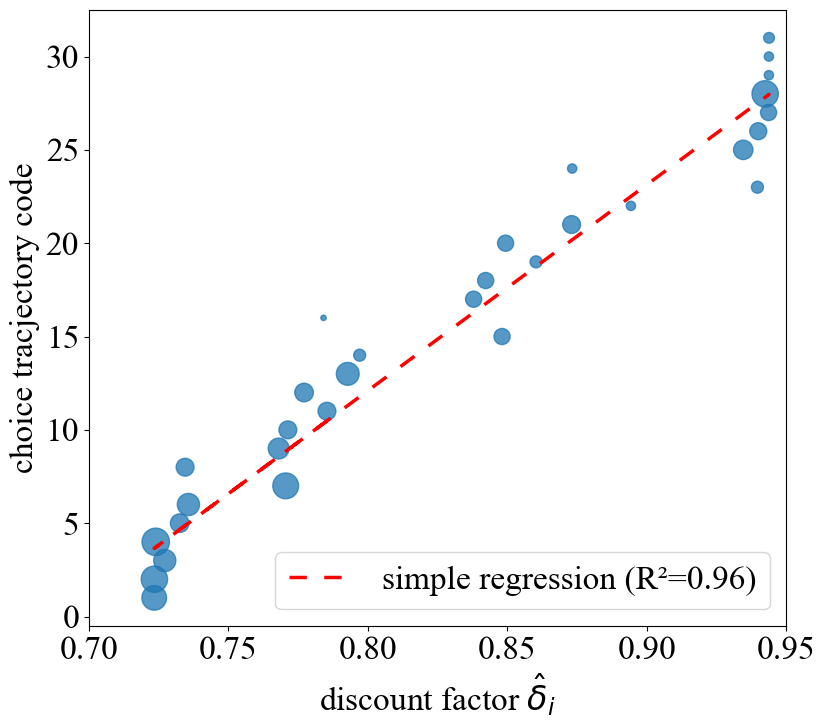

min delta: 0.7234133747929626
max delta: 0.9437860804833382
PearsonRResult(statistic=np.float64(0.9819173178500827), pvalue=np.float64(8.413901222027455e-256))


In [30]:
plt.figure(figsize=(9, 8))

df_scatter_time = df_raw_time.groupby(['delta','v_195']).count()['pid'].reset_index()
plt.scatter(df_scatter_time['delta'],df_scatter_time['v_195'],
            s=df_scatter_time['pid']*15, marker='o', alpha=.75)
plt.xlabel(r'discount factor $\hat{\delta}_i$')
plt.ylabel('choice tracjectory code')
plt.xlim((0.7,0.95))

slope, intercept, r, p_value, std_err = st.linregress(x=df_raw_time['delta'], y=df_raw_time['v_195'])
pred_subgroup = slope * df_raw_time['delta'] + intercept
plt.plot(df_raw_time['delta'], pred_subgroup, color='red', linestyle=(0,(5,5)), linewidth = 2.5, 
         label= f"simple regression (R²={r**2:.2f})")

plt.legend(loc='lower right')
plt.show()

print('min delta:',df_raw_time['delta'].min())
print('max delta:',df_raw_time['delta'].max())
print(st.pearsonr(df_raw_time['delta'],df_raw_time['v_195']))

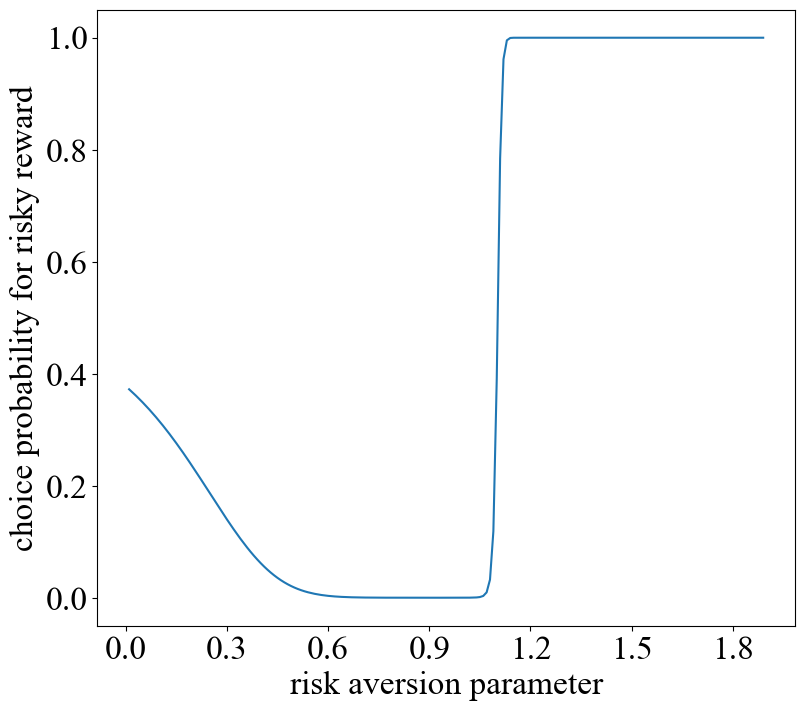

In [37]:
coef = np.arange(0.01,1.9,0.01)

plt.figure(figsize=(9, 8))
plt.plot(coef,1 / (1 + np.exp(- (300**coef * 0.5 - 160**coef))))
plt.xlabel('risk aversion parameter')
plt.ylabel('choice probability for risky reward')
plt.xticks(np.arange(0,2,0.3))
plt.show()

Text(0.5, 0, 'discount factor $\\hat{\\delta}_i$')

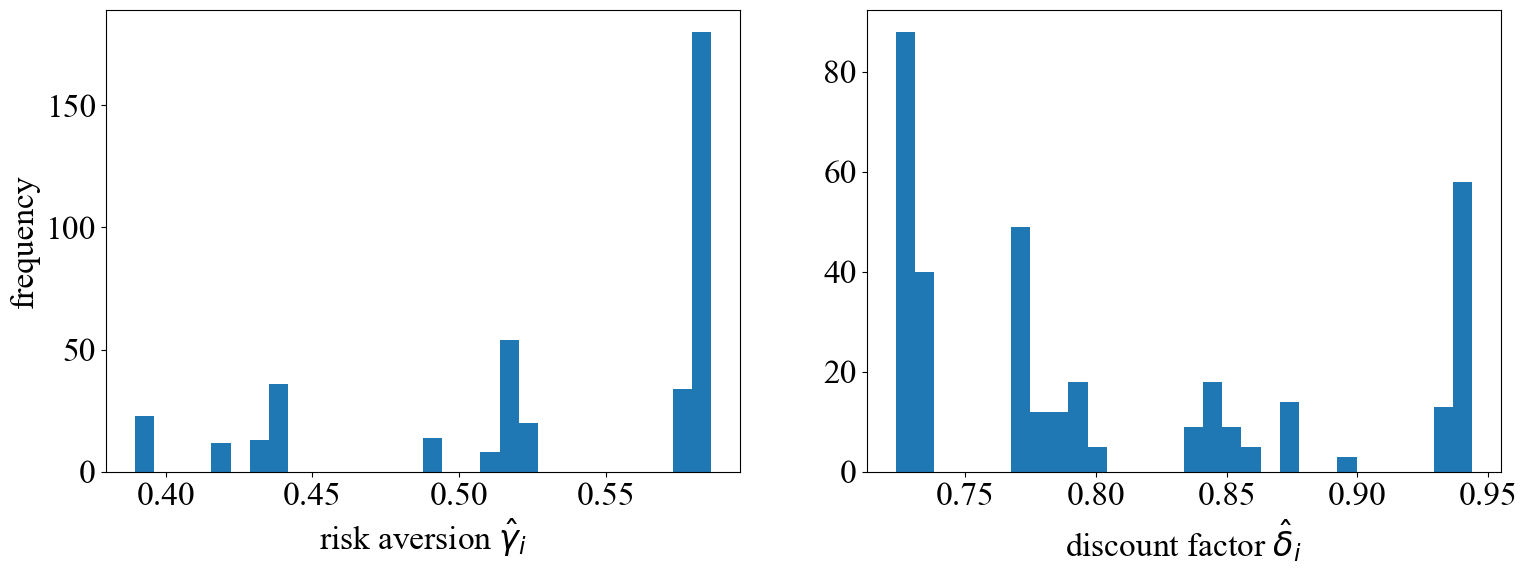

In [10]:
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 24
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

ax1.hist(df_raw_risk['riskCoef'],bins=30)
ax1.set_xlabel(r'risk aversion $\hat{\gamma}_i$')
ax1.set_ylabel('frequency')

ax2.hist(df_raw_time['delta'],bins=30)
ax2.set_xlabel(r'discount factor $\hat{\delta}_i$')

In [ ]:
# Compare model parameter with encoding of choice paths: risky choice
indicators = ['nobs','rsquared_adj','aic']
tab_idx_list = [
                # 'risk-seeking',
                # '',
                r'risk aversion $\hat{\gamma}_i$',
                '',
                'trajectory code',
                '',
                'observations',
                r'adj.$R^2$',
                'AIC',
                ]

rename_encodes = {'v_110':'code'}

col_names = [
            #  'b_const','se_const',
             'b_riskCoef','se_riskCoef',
             'b_code','se_code'] + indicators

def get_reg_table(endog_var): 
    df_raw_risk_edited = df_raw_risk[df_raw_risk[endog_var].notna()].rename(columns=rename_encodes)
    reg_table = pd.DataFrame()
    reg_table.index = col_names

    for var in ['riskCoef','code']:
        X = df_raw_risk_edited[var].astype(float)
        y = df_raw_risk_edited[endog_var]

        _result = sm.OLS(y, sm.add_constant(X)).fit().get_robustcov_results(cov_type='HC1')

        reg_table[var] = [DCM.fill_cell(v,_result,robust_se=True) for v in col_names]

    reg_table.index = tab_idx_list
    reg_table.columns = ['(1) estimated parameter', '(2) choice trajectory']

    return reg_table

reg_table = get_reg_table('x_risk_av') 
DCM.make_table(reg_table,'tables/psm_risk_compare_incentive.tex')

reg_table = get_reg_table('willing_risk') 
DCM.make_table(reg_table,'tables/psm_risk_compare_willing.tex')



In [27]:
# Compare model parameter with encoding of choice paths: intertemporal choice
indicators = ['nobs','rsquared_adj','aic']
tab_idx_list = [
                r'discount factor $\hat{\delta}_i$',
                '',
                'trajectory code',
                '',
                'observations',
                r'adj.$R^2$',
                'AIC',
                ]

rename_encodes = {'v_195':'code'}

col_names = [
            #  'b_const','se_const',
             'b_delta','se_delta',
             'b_code','se_code'] + indicators

def get_reg_table(endog_var): 
    df_raw_time_edited = df_raw_time[df_raw_time[endog_var].notna()].rename(columns=rename_encodes)
    reg_table = pd.DataFrame()
    reg_table.index = col_names

    for var in ['delta','code']:
        X = df_raw_time_edited[var].astype(float)
        y = df_raw_time_edited[endog_var]

        _result = sm.OLS(y, sm.add_constant(X)).fit().get_robustcov_results(cov_type='HC1')

        reg_table[var] = [DCM.fill_cell(v,_result,robust_se=True) for v in col_names]

    reg_table.index = tab_idx_list
    reg_table.columns = ['(1) estimated parameter', '(2) choice trajectory']

    return reg_table

reg_table = get_reg_table('x_time_0_12_av') 
DCM.make_table(reg_table,'tables/psm_time_compare_incentive.tex')

reg_table = get_reg_table('willing_wait') 
DCM.make_table(reg_table,'tables/psm_time_compare_willing.tex')



In [56]:
# Compare model parameter with encoding of choice paths: risky choice
# Plus interaction with risk-seeking behavior
indicators = ['nobs','rsquared_adj','aic']
tab_idx_list_1 = [
                'risk-seeking',
                '',
                r'$\hat{\gamma}_i$',
                '',
                r'$\hat{\gamma}_i$ $\times$ risk-seeking',
                '',
                'observations',
                r'adj.$R^2$',
                'AIC',
                ]

tab_idx_list_2 = [
                'risk-seeking',
                '',
                'trajectory code',
                '',
                r'trajectory code $\times$ risk-seeking',
                '',
                'observations',
                r'adj.$R^2$',
                'AIC',
                ]

col_names_1 = [
            'b_isRiskSeeking','se_isRiskSeeking',
            'b_riskCoef','se_riskCoef',
            'b_riskCoefRiskSeek','se_riskCoefRiskSeek',
            ] + indicators

col_names_2 = [
            'b_isRiskSeeking','se_isRiskSeeking',
            'b_code','se_code',
            'b_codeRiskSeek','se_codeRiskSeek',
            ] + indicators

rename_encodes = {'v_110':'code'}


def get_reg_table(exog_var, col_names, tab_idx_list): 
    reg_table = pd.DataFrame()
    reg_table.index = col_names

    for endog_var in ['x_risk_av','willing_risk']:
        df_raw_risk_edited = df_raw_risk[df_raw_risk[endog_var].notna()].rename(columns=rename_encodes)
        df_raw_risk_edited[f'{exog_var}RiskSeek'] = df_raw_risk_edited[exog_var] * df_raw_risk_edited['isRiskSeeking']

        var_list = ['isRiskSeeking', exog_var, f'{exog_var}RiskSeek']
        X = df_raw_risk_edited[var_list].astype(float)
        y = df_raw_risk_edited[endog_var]

        _result = sm.OLS(y, sm.add_constant(X)).fit().get_robustcov_results(cov_type='HC1')

        reg_table[endog_var] = [DCM.fill_cell(v,_result,robust_se=True) for v in col_names]

    reg_table.index = tab_idx_list
    reg_table.columns = ['(1) incentivized choice', '(2) willingness to take risks']

    return reg_table


reg_table = get_reg_table('riskCoef', col_names_1, tab_idx_list_1) 
DCM.make_table(reg_table,'tables/psm_risk_interaction_riskCoef.tex')

reg_table = get_reg_table('code', col_names_2, tab_idx_list_2) 
DCM.make_table(reg_table,'tables/psm_risk_interaction_code.tex')